# Demo instructor 02 · Interpretabilidad sobre los modelos de ventas

            Esta demo continúa desde la anterior. Carga los mismos modelos de inactividad y propensión y aplica interpretabilidad global y local: importancias, permutation importance, PDP, SHAP y LIME. El objetivo no es explicar por explicar, sino traducir señales del modelo a decisiones comerciales defendibles.


In [1]:
from pathlib import Path
import sys
import warnings
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 160)

def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "datos").exists() and (candidate / "escenarios").exists():
            return candidate
    raise FileNotFoundError("No se ha encontrado la raíz del proyecto FraSoHome.")

PROJECT_ROOT = find_project_root()
DEMO_DIR = PROJECT_ROOT / "escenarios" / "04-analitica-ventas-ml"
ARTIFACT_DIR = DEMO_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(DEMO_DIR))

from common.frasohome_ml import (
    build_campaign_dataset,
    build_churn_dataset,
    build_return_risk_dataset,
    clean_fact_for_ml,
    load_artifact,
    load_operational_tables,
    model_importance,
    prepare_crm,
    prepare_fact,
    save_artifact,
    score_deciles,
    train_binary_model,
    transformed_feature_names,
)

print("PROJECT_ROOT:", PROJECT_ROOT)

from sklearn.inspection import PartialDependenceDisplay, permutation_importance
import shap
from lime import lime_tabular


PROJECT_ROOT: C:\repos\frasohome-demos


## 1. Carga del artefacto generado en la demo de ventas


In [2]:
artifact = load_artifact(ARTIFACT_DIR / "sales_models_artifact.joblib")
print("Creado:", artifact["created_at"])
churn = artifact["churn"]
campaign = artifact["campaign"]


Creado: 2026-06-07T12:12:32


## 2. Importancia global

            Las importancias internas ayudan a abrir conversación, pero no son causalidad. Sirven para detectar qué señales está usando el modelo y si esas señales tienen sentido comercial.


In [3]:
display(pd.Series(churn["result"]["metrics"]).to_frame("churn"))
display(model_importance(churn["result"]["pipeline"], top_n=20))
display(pd.Series(campaign["result"]["metrics"]).to_frame("campaign"))
display(model_importance(campaign["result"]["pipeline"], top_n=20))


,churn
rows,596.000000
target_rate,0.473154
test_roc_auc,0.755515
test_average_precision,0.768213
test_f1,0.619048
test_accuracy,0.677852


,feature,importance,abs_value
0,points,0.062205,0.062205
1,margin_gross,0.035031,0.035031
2,avg_order_value,0.033205,0.033205
3,avg_sla_hours,0.031737,0.031737
4,ciudad_Córdoba,0.029915,0.029915
5,avg_unit_price,0.028762,0.028762
6,pct_high_priority_tickets,0.028633,0.028633
7,gross_margin_rate,0.028455,0.028455
8,monetary_gross,0.024707,0.024707
9,revenue_cat_muebles,0.023961,0.023961


,campaign
rows,158.000000
target_rate,0.367089
test_roc_auc,0.688000
test_average_precision,0.646215
test_f1,0.451613
test_accuracy,0.575000


,feature,importance,abs_value
0,customer_tenure_window_days,0.058811,0.058811
1,revenue_channel_pos,0.056124,0.056124
2,margin_gross,0.033939,0.033939
3,gross_margin_rate,0.031391,0.031391
4,frequency_docs,0.031252,0.031252
5,avg_unit_price,0.026211,0.026211
6,avg_nps,0.025555,0.025555
7,monetary_gross,0.024387,0.024387
8,revenue_cat_textil_hogar,0.024125,0.024125
9,units_sold,0.019921,0.019921


## 3. Permutation importance sobre test


In [4]:
def permutation_table(result, target_name):
    perm = permutation_importance(
        result["pipeline"], result["X_test"], result["y_test"],
        scoring="roc_auc", n_repeats=8, random_state=42, n_jobs=-1,
    )
    return pd.DataFrame({
        "target": target_name,
        "feature": result["X_test"].columns,
        "mean_auc_drop": perm.importances_mean,
        "std": perm.importances_std,
    }).sort_values("mean_auc_drop", ascending=False)

display(permutation_table(churn["result"], "inactividad").head(12))
display(permutation_table(campaign["result"], "propensión").head(12))


,target,feature,mean_auc_drop,std
32,inactividad,points,0.024401,0.011462
31,inactividad,tier_fidelizacion,0.013201,0.005151
35,inactividad,origen_alta,0.008431,0.002742
37,inactividad,ciudad,0.007075,0.009102
38,inactividad,provincia,0.006600,0.005484
24,inactividad,revenue_cat_muebles,0.006555,0.003360
13,inactividad,gross_margin_rate,0.006487,0.001541
9,inactividad,n_products,0.005945,0.001624
23,inactividad,revenue_cat_iluminacion,0.005877,0.001999
44,inactividad,web_value_sum,0.005832,0.001536


,target,feature,mean_auc_drop,std
4,propensión,offer_code,0.010667,0.009043
61,propensión,avg_nps,0.004000,0.004422
8,propensión,prioridad_contacto,0.003333,0.006498
46,propensión,origen_alta,0.002667,0.002667
52,propensión,web_events,0.002667,0.004619
53,propensión,web_sessions,0.002333,0.003109
57,propensión,web_searches,0.002333,0.006173
26,propensión,gross_margin_rate,0.002000,0.007513
10,propensión,product_id_recomendado_1,0.002000,0.006498
54,propensión,web_active_days,0.001667,0.001856


## 4. PDP: sensibilidad media de variables accionables


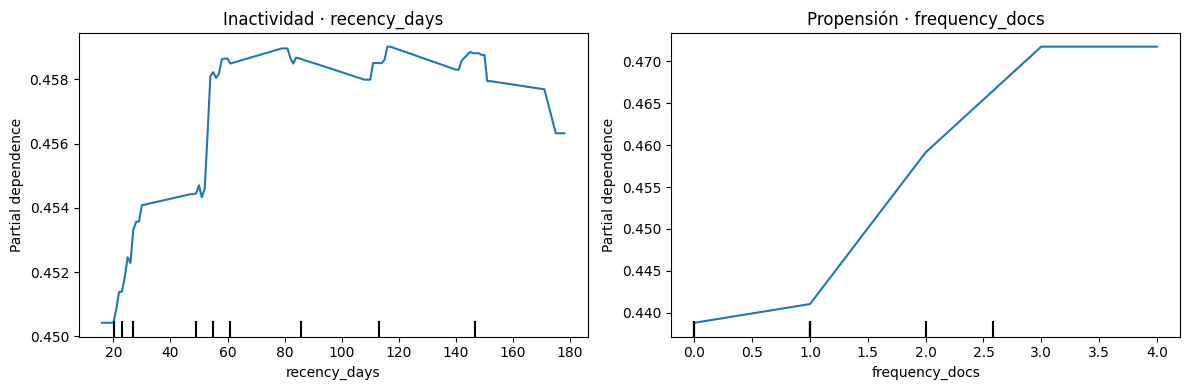

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(churn["result"]["pipeline"], churn["result"]["X_test"], ["recency_days"], ax=axes[0])
axes[0].set_title("Inactividad · recency_days")
PartialDependenceDisplay.from_estimator(campaign["result"]["pipeline"], campaign["result"]["X_test"], ["frequency_docs"], ax=axes[1])
axes[1].set_title("Propensión · frequency_docs")
plt.tight_layout()
plt.show()


## 5. SHAP global y local


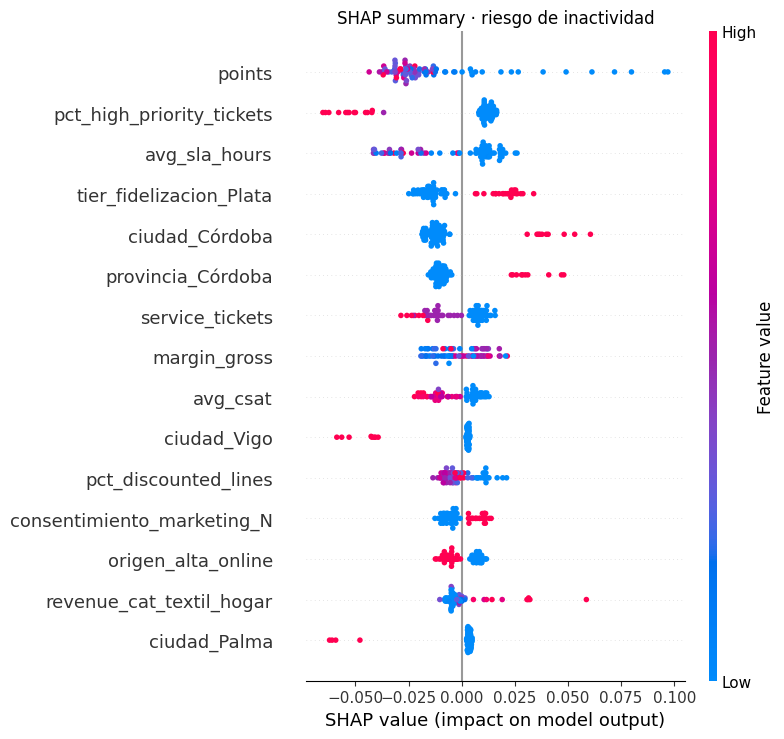

In [6]:
def shap_values_for_tree_pipeline(result, sample_size=80):
    pipe = result["pipeline"]
    pre = pipe.named_steps["preprocess"]
    model = pipe.named_steps["model"]
    X_sample = result["X_test"].sample(min(sample_size, len(result["X_test"])), random_state=42)
    X_trans = pre.transform(X_sample)
    feature_names = transformed_feature_names(pipe)
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(X_trans)
    if isinstance(values, list):
        values = values[1]
    elif hasattr(values, "ndim") and values.ndim == 3:
        values = values[:, :, 1]
    return X_sample, X_trans, feature_names, values

X_sample, X_trans, names, values = shap_values_for_tree_pipeline(churn["result"])
shap.summary_plot(values, X_trans, feature_names=names, show=False, max_display=15)
plt.title("SHAP summary · riesgo de inactividad")
plt.tight_layout()
plt.show()


In [7]:
def local_shap_table(result, top_n=12):
    pipe = result["pipeline"]
    pre = pipe.named_steps["preprocess"]
    model = pipe.named_steps["model"]
    X_test = result["X_test"]
    scores = pipe.predict_proba(X_test)[:, 1]
    row_position = int(np.argmax(scores))
    row_raw = X_test.iloc[[row_position]]
    row_trans = pre.transform(row_raw)
    feature_names = transformed_feature_names(pipe)
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(row_trans)
    if isinstance(values, list):
        values = values[1][0]
    elif hasattr(values, "ndim") and values.ndim == 3:
        values = values[0, :, 1]
    else:
        values = values[0]
    out = pd.DataFrame({"feature": feature_names, "shap_value": values})
    out["abs_value"] = out["shap_value"].abs()
    return scores[row_position], row_raw, out.sort_values("abs_value", ascending=False).head(top_n)

score, row_raw, explanation = local_shap_table(churn["result"])
print(f"Score alto de inactividad: {score:.3f}")
display(row_raw.T.head(25))
display(explanation)


Score alto de inactividad: 0.947


,593
frequency_docs,1
sales_lines,1
units_sold,1.0
monetary_gross,309.5
margin_gross,0.0
avg_discount_pct,0.0
pct_discounted_lines,0.0
avg_unit_price,309.5
n_categories,0
n_products,1


,feature,shap_value,abs_value
27,points,0.079852,0.079852
100,ciudad_Córdoba,0.060542,0.060542
123,provincia_Córdoba,0.048018,0.048018
77,tier_fidelizacion_Plata,0.021434,0.021434
42,avg_sla_hours,0.018052,0.018052
44,pct_high_priority_tickets,0.013971,0.013971
86,consentimiento_marketing_N,0.013849,0.013849
4,margin_gross,0.012040,0.012040
41,service_tickets,0.011945,0.011945
6,pct_discounted_lines,0.010853,0.010853


## 6. LIME para una explicación local de campaña


In [8]:
def lime_explanation(result, top_n=10):
    pipe = result["pipeline"]
    pre = pipe.named_steps["preprocess"]
    model = pipe.named_steps["model"]
    X_train_trans = pre.transform(result["X_train"])
    X_test_trans = pre.transform(result["X_test"])
    feature_names = transformed_feature_names(pipe)
    scores = pipe.predict_proba(result["X_test"])[:, 1]
    row_position = int(np.argmax(scores))
    explainer = lime_tabular.LimeTabularExplainer(
        training_data=np.asarray(X_train_trans, dtype=float),
        feature_names=feature_names,
        class_names=["no", "sí"],
        mode="classification",
        discretize_continuous=True,
        random_state=42,
    )
    exp = explainer.explain_instance(
        np.asarray(X_test_trans[row_position], dtype=float),
        model.predict_proba,
        num_features=top_n,
    )
    return scores[row_position], pd.DataFrame(exp.as_list(), columns=["condición local", "peso"])

score, lime_table = lime_explanation(campaign["result"])
print(f"Score alto de conversión: {score:.3f}")
display(lime_table)


Score alto de conversión: 0.699


,condición local,peso
0,consentimiento_marketing_sí <= 0.00,0.027354
1,margin_gross > 0.08,0.020909
2,avg_nps <= -0.46,-0.020833
3,-0.58 < customer_tenure_window_days <= 0.13,-0.019409
4,last_store_id_ONLINE <= 0.00,0.017391
5,revenue_cat_muebles > -0.05,0.017302
6,units_sold > 0.31,0.017215
7,-0.09 < frequency_docs <= 0.76,0.016774
8,web_value_sum > -0.42,0.015998
9,recency_days > 0.66,-0.015246


## 7. Traducción final a negocio

            Una explicación útil termina en acción: priorizar deciles, personalizar canal/categoría, revisar experiencia posventa y monitorizar estabilidad. La cautela central es no confundir explicación predictiva con causalidad.
